# Khám phá và tiền xử lý dữ liệu

## Mini Capstone Machine Learning

Notebook này phục vụ giai đoạn xác minh dataset, khám phá dữ liệu và thống nhất tiền xử lý. Notebook **không** huấn luyện hoặc đánh giá mô hình; các phần đó sẽ được thực hiện ở giai đoạn sau trên cùng quy ước dữ liệu.

## 1. Nguồn dữ liệu

- File được nhóm tải từ Kaggle và lưu tại `data/Craw_data/data.csv`.
- Nguồn Kaggle: [Breast Cancer Wisconsin Diagnostic](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data).
- Nguồn tham chiếu: [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic).
- Bài toán là phân loại nhị phân: `B` là lành tính và `M` là ác tính.

Dữ liệu gốc được giữ nguyên; tất cả thao tác trong notebook chạy trên bản đọc vào bộ nhớ.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', palette='Set2')

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent

data_path = project_root / 'data' / 'Craw_data' / 'data.csv'
if not data_path.exists():
    raise FileNotFoundError(f'Không tìm thấy dữ liệu tại: {data_path}')

print(f'Đang dùng file: {data_path}')

Đang dùng file: D:\Project_AIL303m\data\Craw_data\data.csv


## 2. Đọc dữ liệu và xác minh cấu trúc

Mục tiêu của bước này là xác nhận file CSV thực tế có đúng cấu trúc mong đợi trước khi làm sạch dữ liệu.

In [2]:
raw_data = pd.read_csv(data_path)

print(f'Kích thước file gốc: {raw_data.shape[0]} hàng x {raw_data.shape[1]} cột')
print('\nTên các cột:')
print(raw_data.columns.tolist())
print('\nKiểu dữ liệu:')
print(raw_data.dtypes)

raw_data.head()

Kích thước file gốc: 569 hàng x 33 cột

Tên các cột:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Kiểu dữ liệu:
id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
sy

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 3. Kiểm tra chất lượng dữ liệu

Kiểm tra giá trị thiếu, cột rỗng hoàn toàn, hàng trùng lặp và mã bản ghi trùng. Một số file export có cột `Unnamed: 32` rỗng hoàn toàn; cần xác minh đây là cột kỹ thuật trước khi loại bỏ.

In [3]:
quality_report = pd.DataFrame({
    'kieu_du_lieu': raw_data.dtypes.astype(str),
    'so_gia_tri_thieu': raw_data.isna().sum(),
    'so_gia_tri_khac_nhau': raw_data.nunique(dropna=True),
})

print('Các cột có giá trị thiếu:')
display(quality_report[quality_report['so_gia_tri_thieu'] > 0])
print(f'Số hàng trùng hoàn toàn: {raw_data.duplicated().sum()}')
print(f'Số mã id trùng: {raw_data['id'].duplicated().sum()}')

quality_report

Các cột có giá trị thiếu:


,kieu_du_lieu,so_gia_tri_thieu,so_gia_tri_khac_nhau
Unnamed: 32,float64,569,0


Số hàng trùng hoàn toàn: 0
Số mã id trùng: 0


,kieu_du_lieu,so_gia_tri_thieu,so_gia_tri_khac_nhau
id,int64,0,569
diagnosis,object,0,2
radius_mean,float64,0,456
texture_mean,float64,0,479
perimeter_mean,float64,0,522
area_mean,float64,0,539
smoothness_mean,float64,0,474
compactness_mean,float64,0,537
concavity_mean,float64,0,537
concave points_mean,float64,0,542


## 4. Tiền xử lý dữ liệu

Quy tắc được áp dụng trong notebook này:

1. Chỉ xóa cột rỗng **hoàn toàn** do định dạng file.
2. Giữ lại mọi cột dữ liệu thực; nếu còn dữ liệu thiếu thì phải thảo luận cách xử lý trước khi tiếp tục.
3. Không dùng `id` làm đặc trưng dự đoán.
4. Mã hóa nhãn thống nhất: `B = 0`, `M = 1`.

In [4]:
data = raw_data.dropna(axis="columns", how="all").copy()

if data.isna().any().any():
    raise ValueError('Còn giá trị thiếu trong các cột dữ liệu thực. Hãy thống nhất cách xử lý trước.')
if not data['diagnosis'].isin(['B', 'M']).all():
    raise ValueError('Cột diagnosis chỉ được chứa B hoặc M.')

X = data.drop(columns=["id", "diagnosis"]).copy()
y = data['diagnosis'].map({"B": 0, "M": 1})

print(f'Dữ liệu sau làm sạch: {data.shape[0]} mẫu, {X.shape[1]} đặc trưng số')
print('Quy ước nhãn: 0 = B (lành tính), 1 = M (ác tính)')
X.head()

Dữ liệu sau làm sạch: 569 mẫu, 30 đặc trưng số
Quy ước nhãn: 0 = B (lành tính), 1 = M (ác tính)


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### 4.1. Lưu dữ liệu đã làm sạch

Bước này tạo một file dẫn xuất riêng, không làm thay đổi file CSV gốc. File sạch giữ nhãn `diagnosis` ở dạng `B/M` để tiện kiểm tra; chỉ loại cột `id` và cột rỗng hoàn toàn đã được xác minh ở trên.

In [5]:
# Lưu bản dữ liệu sạch để cả ba mô hình dùng chung ở giai đoạn sau
clean_data = data.drop(columns=["id"]).copy()
clean_data_path = project_root / 'data' / 'processed' / 'breast_cancer_clean.csv'
clean_data_path.parent.mkdir(parents=True, exist_ok=True)
clean_data.to_csv(clean_data_path, index=False)

removed_columns = sorted(set(raw_data.columns) - set(clean_data.columns))
print(f'Đã lưu file: {clean_data_path}')
print(f'Kích thước dữ liệu sạch: {clean_data.shape[0]} hàng x {clean_data.shape[1]} cột')
print(f'Các cột đã loại: {removed_columns}')
display(clean_data.head())

Đã lưu file: D:\Project_AIL303m\data\processed\breast_cancer_clean.csv
Kích thước dữ liệu sạch: 569 hàng x 31 cột
Các cột đã loại: ['Unnamed: 32', 'id']


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 5. Khám phá dữ liệu

### 5.1. Phân bố nhãn

Phân bố lớp giúp nhóm đánh giá mức độ cân bằng dữ liệu và nhắc lại lý do phải dùng chia dữ liệu có `stratify` ở giai đoạn mô hình.

,so_mau,ty_le_phan_tram
nhan,,
Lành tính,357,62.74
Ác tính,212,37.26


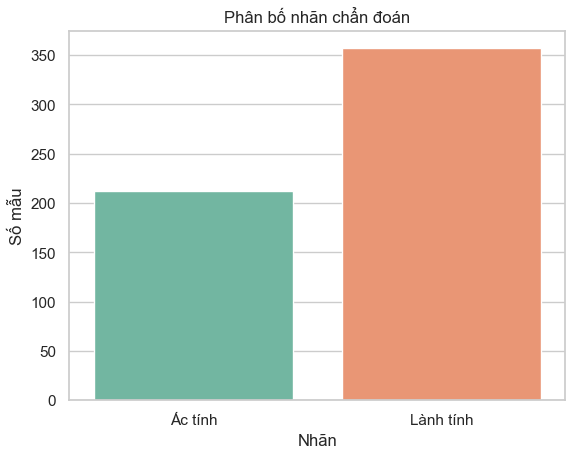

In [6]:
label_names = data['diagnosis'].map({'B': 'Lành tính', 'M': 'Ác tính'})
class_summary = label_names.value_counts().rename_axis('nhan').to_frame('so_mau')
class_summary['ty_le_phan_tram'] = (class_summary['so_mau'] / len(data) * 100).round(2)
display(class_summary)

ax = sns.countplot(x=label_names, hue=label_names, legend=False)
ax.set(title='Phân bố nhãn chẩn đoán', xlabel='Nhãn', ylabel='Số mẫu')
plt.show()

### 5.2. Thống kê mô tả

Các cột có thang đo khác nhau. Quan sát này sẽ được dùng để biện minh cho việc chuẩn hóa trong các notebook mô hình cần phụ thuộc vào khoảng cách hoặc biên phân tách.

In [7]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


### 5.3. Tương quan giữa đặc trưng và nhãn

Tương quan chỉ mô tả mối liên hệ tuyến tính, không chứng minh quan hệ nhân quả. Bảng này được dùng để định hướng phần giải thích dataset trong báo cáo đầu tiên.

,tuong_quan_voi_nhan_ac_tinh
concave points_worst,0.793566
perimeter_worst,0.782914
concave points_mean,0.776614
radius_worst,0.776454
perimeter_mean,0.742636
area_worst,0.733825
radius_mean,0.730029
area_mean,0.708984
concavity_mean,0.696360
concavity_worst,0.659610


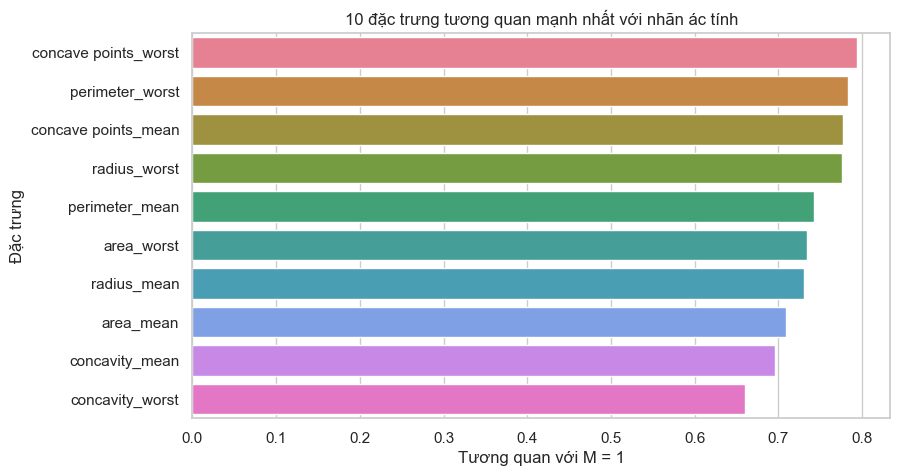

In [8]:
feature_target_correlation = X.corrwith(y).sort_values(key=lambda values: values.abs(), ascending=False)
display(feature_target_correlation.rename('tuong_quan_voi_nhan_ac_tinh').to_frame().head(10))

top_features = feature_target_correlation.head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=top_features.values, y=top_features.index, hue=top_features.index, legend=False)
plt.title('10 đặc trưng tương quan mạnh nhất với nhãn ác tính')
plt.xlabel('Tương quan với M = 1')
plt.ylabel('Đặc trưng')
plt.show()

### 5.4. Ma trận tương quan

Biểu đồ giúp nhận diện các đặc trưng đo những khía cạnh gần nhau. Nhóm sẽ không loại đặc trưng chỉ dựa vào biểu đồ này; mọi quyết định sau đó phải được ghi rõ và thực hiện trong pipeline để tránh rò rỉ dữ liệu.

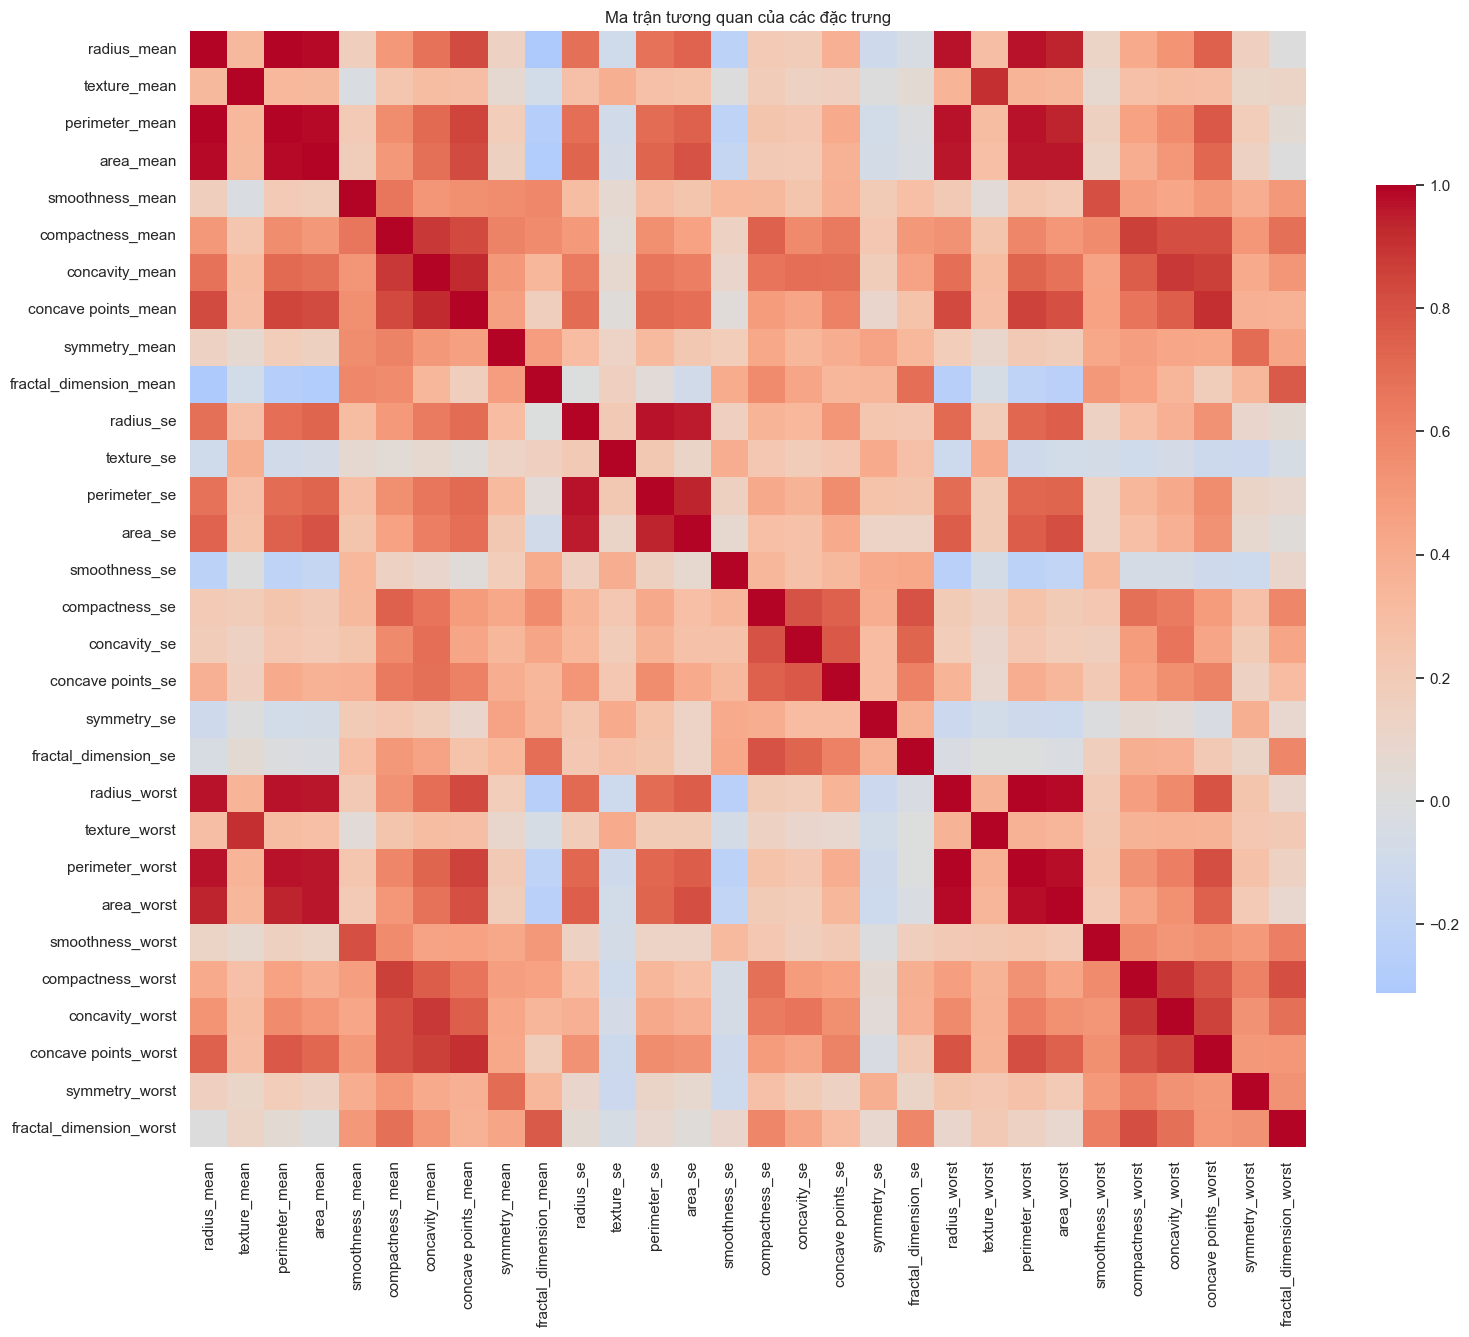

In [9]:
plt.figure(figsize=(18, 15))
sns.heatmap(X.corr(), cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': 0.7})
plt.title('Ma trận tương quan của các đặc trưng')
plt.show()

## 6. Chuẩn bị dữ liệu cho giai đoạn mô hình

Đầu ra của notebook này là `X` và `y` đã được xác minh. Trước khi bắt đầu thử nghiệm, cả nhóm sẽ dùng chung quy ước sau:

- Chia train/test 80/20, giữ tỷ lệ lớp bằng `stratify`, với `random_state = 42`.
- Tập test được giữ độc lập và không dùng để chọn siêu tham số.
- Các phép biến đổi phụ thuộc dữ liệu, như chuẩn hóa hoặc lựa chọn đặc trưng, chỉ được fit trên dữ liệu huấn luyện trong từng fold.
- Kết quả EDA là mô tả dữ liệu; chưa phải kết quả đánh giá mô hình.

## 7. Kết luận giai đoạn dữ liệu

Sau khi chạy notebook, nhóm cần ghi vào báo cáo đầu tiên: số mẫu/cột xác minh được, tình trạng cột rỗng, dữ liệu thiếu và trùng lặp, tỷ lệ hai nhãn, cùng các đặc trưng có tương quan đáng chú ý. Giai đoạn tiếp theo chỉ bắt đầu khi cả nhóm đã rà soát các quan sát này và chấp nhận quy ước tiền xử lý.